# Foundations 9: Geometry and conic sections

*Learning path: foundations, part 9 of 9.* [Index](README.md) · Previous: [Differential equations](08-differential-equations.ipynb)

Descartes' great idea was to describe shapes by equations in coordinates $x$ and $y$. Then geometry becomes algebra,
and a computer algebra system becomes a geometry machine. This lesson goes from points and lines to the **conic
sections**: circles, ellipses, parabolas and hyperbolas, the curves of planetary orbits, satellite dishes and
cooling towers. You will learn

* distances, lines and their intersections,
* how to draw a curve given by an equation with `implicitplot`,
* the circle, ellipse, parabola and hyperbola, and their focus properties,
* how to **classify any conic** $Ax^2 + Bxy + Cy^2 + Dx + Ey + F = 0$ with the discriminant $B^2 - 4AC$,
* how to rotate a tilted conic into standard position with eigenvalues,
* the degenerate cases, and the eccentricity that unites all conics.

## 1. Points, distances and lines

The distance between $(x_1, y_1)$ and $(x_2, y_2)$ is Pythagoras: $\sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$. As a
function:

In [1]:
dist(x1, y1, x2, y2) := sqrt((x2 - x1)^2 + (y2 - y1)^2);
dist(1, 2, 4, 6)
dist(0, 0, a, b)

5

sqrt(a^2+b^2)

A (non-vertical) line is $y = mx + c$, with **slope** $m$ (how much $y$ rises when $x$ increases by 1) and
**intercept** $c$ (where it crosses the vertical axis). The line through two points has the slope
$m = \frac{y_2 - y_1}{x_2 - x_1}$. Two lines meet where both equations hold, so their intersection is a system of
equations:

In [2]:
solve([y == 2*x - 1, y == -x + 5], [x, y])

[2, 3]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

The lines $y = 2x - 1$ and $y = -x + 5$ meet at $(2, 3)$. Two lines are **perpendicular** when their slopes multiply
to $-1$: $y = 2x - 1$ and $y = -x/2 + 4$ are, and that shows if both axes use the same scale. `parametric` draws
with equal scales: the line $y = mx + c$ is the set of points $(t, mt + c)$.

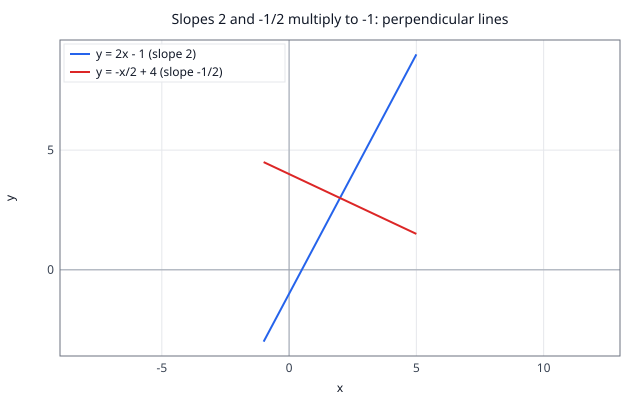

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
l1 = parametric(t, 2*t - 1, t, -1, 5);
l2 = parametric(t, -t/2 + 4, t, -1, 5);
p = legend(show(l1, l2), "y = 2x - 1 (slope 2)", "y = -x/2 + 4 (slope -1/2)");
labels(title(p, "Slopes 2 and -1/2 multiply to -1: perpendicular lines"), "x", "y")

## 2. Curves given by an equation

The circle with centre $(a, b)$ and radius $r$ is the set of points at distance $r$ from the centre:

$$(x - a)^2 + (y - b)^2 = r^2.$$

This equation does not say "$y = $ something", so `plot` cannot draw it. `implicitplot` can. Its arguments:

```
implicitplot(equation, x, x0, x1, y, y0, y1)
```

* **equation**: the curve, written with `==` (or an expression $F$, meaning $F = 0$);
* **x, x0, x1**: the horizontal variable and the window from $x_0$ to $x_1$;
* **y, y0, y1**: the vertical variable and the window from $y_0$ to $y_1$.

Galileo computes the difference of the two sides on a 200 × 200 grid of points in the window and traces the curve where
the sign changes. Both axes use the same scale, so circles look round. A list of equations draws several curves.

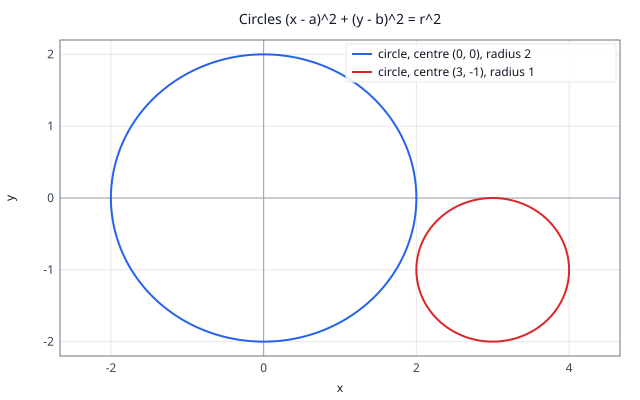

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
p = implicitplot([x^2 + y^2 == 4, (x - 3)^2 + (y + 1)^2 == 1], x, -3, 5, y, -3, 3);
p = legend(p, "circle, centre (0, 0), radius 2", "circle, centre (3, -1), radius 1");
labels(title(p, "Circles (x - a)^2 + (y - b)^2 = r^2"), "x", "y")

Multiplied out, a circle equation looks like $x^2 + y^2 + Dx + Ey + F = 0$. To find the centre again, **complete the
square**: $x^2 - 6x = (x - 3)^2 - 9$. Galileo can check such rewritings:

In [5]:
expand((x - 3)^2 + (y + 1)^2 - 1)

x^2-6*x+y^2+2*y+9

> `expand`: Multiplies out products and powers.

So $x^2 - 6x + y^2 + 2y + 9 = 0$ is the circle with centre $(3, -1)$ and radius 1.

## 3. The conic sections

Cut a double cone with a plane. Depending on the tilt of the plane you get a **circle** (plane flat), an **ellipse**
(slightly tilted), a **parabola** (parallel to the side of the cone) or a **hyperbola** (steeper, cutting both halves).
Apollonius of Perga wrote eight books about these curves around 200 BC. Here is the double cone $z^2 = x^2 + y^2$,
drawn with `surface(X, Y, Z, u, u0, u1, v, v0, v1)` as the points $(r\cos t, r\sin t, r)$; drag to rotate it:

The plane is $z = 0.6x + 0.5$, drawn as the points $(u, v, 0.6u + 0.5)$. Where it cuts the cone, $z = r$ and
$r = 0.6\,r\cos t + 0.5$, so $r = 0.5/(1 - 0.6\cos t)$: the black curve, drawn with
`parametric3d(X, Y, Z, t, from, to)`.

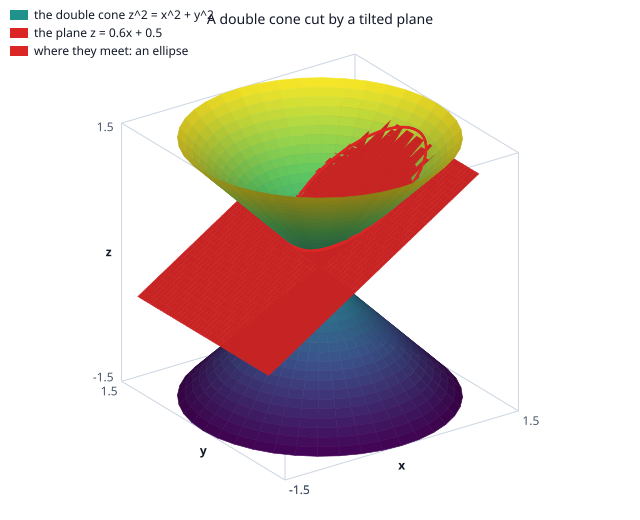

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
cone = surface(r*cos(t), r*sin(t), r, r, -1.5, 1.5, t, 0, 2*pi);
plane = surface(u, v, 0.6*u + 0.5, u, -1.5, 1.2, v, -1.2, 1.2);
rr = 0.5/(1 - 0.6*cos(t));
cut = parametric3d(rr*cos(t), rr*sin(t), rr, t, 0, 2*pi);
p = legend(show(cone, plane, cut), "the double cone z^2 = x^2 + y^2", "the plane z = 0.6x + 0.5", "where they meet: an ellipse");
labels(title(p, "A double cone cut by a tilted plane"), "x", "y", "z")

In coordinates, each conic has a standard form:

| conic | standard equation | definition |
|---|---|---|
| ellipse | $\dfrac{x^2}{a^2} + \dfrac{y^2}{b^2} = 1$ | sum of distances to two foci is constant ($2a$) |
| hyperbola | $\dfrac{x^2}{a^2} - \dfrac{y^2}{b^2} = 1$ | difference of distances to two foci is constant ($2a$) |
| parabola | $y = \dfrac{x^2}{4p}$ | same distance to the focus $(0, p)$ and the line $y = -p$ |

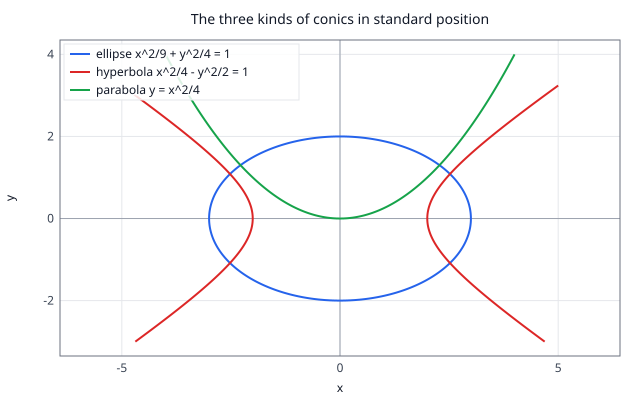

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
p = implicitplot([x^2/9 + y^2/4 == 1, x^2/4 - y^2/2 == 1, y == x^2/4], x, -5, 5, y, -3, 4);
p = legend(p, "ellipse x^2/9 + y^2/4 = 1", "hyperbola x^2/4 - y^2/2 = 1", "parabola y = x^2/4");
labels(title(p, "The three kinds of conics in standard position"), "x", "y")

### The foci of the ellipse

For $\frac{x^2}{a^2} + \frac{y^2}{b^2} = 1$ with $a > b$ the foci are at $(\pm c, 0)$ with $c = \sqrt{a^2 - b^2}$. Let's
check the definition: take the point of the ellipse at angle $t$, $(a\cos t, b\sin t)$, add its distances to the two
foci, and simplify:

In [8]:
a = 3; b = 2;
c = sqrt(a^2 - b^2)
d1 = dist(a*cos(t), b*sin(t), c, 0);
d2 = dist(a*cos(t), b*sin(t), -c, 0);
eval(table(d1 + d2, t, [0, 0.5, 1, 2, 3]))
clear

sqrt(5)

> `sqrt`: Square root; sqrt(-1) is the imaginary unit i.

[6.0, 6.0, 6.0, 6.0, 6.000000000000001]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The sum is $2a = 6$ at every point. That is the gardener's construction: tie a string of length $2a$ to two pegs at
the foci, pull it tight with a stick, and walk around. A light ray from one focus reflects off the ellipse into the
other; for the parabola, rays from the focus leave parallel, which is why satellite dishes and headlights are
parabolic.

### The hyperbola's asymptotes

Far from the centre, $\frac{x^2}{a^2} - \frac{y^2}{b^2} = 1$ looks like $\frac{x^2}{a^2} = \frac{y^2}{b^2}$, the two
lines $y = \pm\frac ba x$:

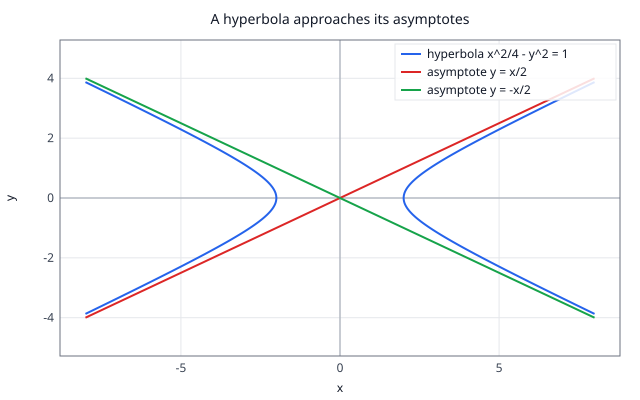

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
p = implicitplot([x^2/4 - y^2 == 1, y == x/2, y == -x/2], x, -8, 8, y, -4, 4);
p = legend(p, "hyperbola x^2/4 - y^2 = 1", "asymptote y = x/2", "asymptote y = -x/2");
labels(title(p, "A hyperbola approaches its asymptotes"), "x", "y")

## 4. Classifying any conic

Every conic is given by a second-degree equation

$$A x^2 + B xy + C y^2 + D x + E y + F = 0.$$

Which kind it is depends only on the **discriminant** $B^2 - 4AC$:

* $B^2 - 4AC < 0$: an **ellipse** (a circle if $B = 0$ and $A = C$),
* $B^2 - 4AC = 0$: a **parabola**,
* $B^2 - 4AC > 0$: a **hyperbola**.

(This is the same discriminant as for quadratic equations, for a good reason: it tells whether the curve has real
directions going off to infinity.) We can let Galileo do the classification with a function that uses `if`:
`if(condition, a, b)` gives $a$ when the condition is true and $b$ otherwise; conditions use `<`, `>`, `==`.

In [10]:
kind(A, B, C) := if(B^2 - 4*A*C < 0, "ellipse", if(B^2 - 4*A*C == 0, "parabola", "hyperbola"));
kind(1, 0, 1)
kind(5, 4, 2)
kind(1, 2, 1)
kind(0, 1, 0)

"ellipse"
"ellipse"
"parabola"
"hyperbola"

So $5x^2 + 4xy + 2y^2 = 1$ is an ellipse, $x^2 + 2xy + y^2 = x$ is a parabola, and $xy = 1$ is a hyperbola. They are
tilted, because of the $xy$ term:

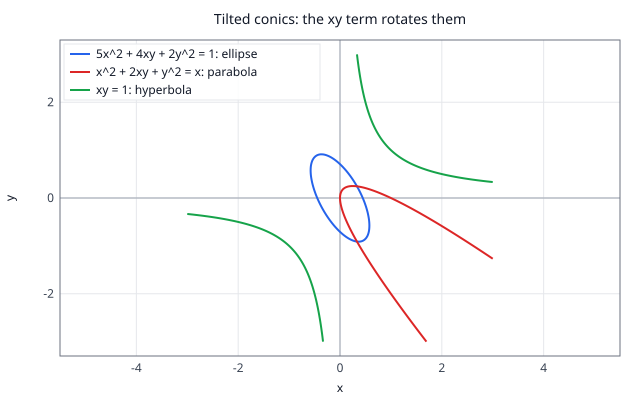

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
p = implicitplot([5*x^2 + 4*x*y + 2*y^2 == 1, x^2 + 2*x*y + y^2 == x, x*y == 1], x, -3, 3, y, -3, 3);
p = legend(p, "5x^2 + 4xy + 2y^2 = 1: ellipse", "x^2 + 2xy + y^2 = x: parabola", "xy = 1: hyperbola");
labels(title(p, "Tilted conics: the xy term rotates them"), "x", "y")

## 5. Untilting a conic with eigenvalues

The quadratic part $Ax^2 + Bxy + Cy^2$ can be written with the symmetric matrix

$$M = \begin{pmatrix} A & B/2 \\ B/2 & C\end{pmatrix}, \qquad Ax^2 + Bxy + Cy^2 = \begin{pmatrix}x & y\end{pmatrix} M \begin{pmatrix}x\\y\end{pmatrix}.$$

Rotating the coordinates to the directions of $M$'s **eigenvectors** removes the $xy$ term, and the new coefficients
are the **eigenvalues** $\lambda_1, \lambda_2$ of $M$. For $5x^2 + 4xy + 2y^2$:

In [12]:
M = [5 2; 2 2];
eig(M)
det(M)

[1, 6]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

6

> `det`: Determinant.

The eigenvalues are 1 and 6, so in rotated coordinates $(u, v)$ the ellipse is $u^2 + 6v^2 = 1$ (or $6u^2 + v^2 = 1$,
depending on which axis is which). The signs of the eigenvalues give the classification again: both the same sign
means ellipse, opposite signs hyperbola, a zero eigenvalue parabola. Since $\det M = \lambda_1\lambda_2 =
AC - B^2/4 = -\frac14(B^2 - 4AC)$, this is the discriminant test in disguise.

The rotation angle $\theta$ satisfies $\tan 2\theta = B/(A - C) = 4/3$, so $\cos\theta = 2/\sqrt5$ and
$\sin\theta = 1/\sqrt5$. Substituting the rotation $x = u\cos\theta - v\sin\theta$, $y = u\sin\theta + v\cos\theta$
confirms it:

In [13]:
c = 2/sqrt(5); s = 1/sqrt(5);
expand(subs(subs(5*x^2 + 4*x*y + 2*y^2, x, c*u - s*v), y, s*u + c*v))

6*u^2+v^2

> `expand`: Multiplies out products and powers.

The $xy$ term is gone: the ellipse is $6u^2 + v^2 = 1$, with half-axes $1/\sqrt6$ and $1$. The hyperbola $xy = 1$
rotated by $45^\circ$ is the standard hyperbola $\frac{u^2}{2} - \frac{v^2}{2} = 1$:

In [14]:
expand(subs(subs(x*y, x, (u - v)/sqrt(2)), y, (u + v)/sqrt(2)))
clear

u^2/2-v^2/2

> `expand`: Multiplies out products and powers.

### Degenerate conics

Some second-degree equations give no proper curve at all: $x^2 - y^2 = 0$ is the pair of lines $y = \pm x$,
$x^2 + y^2 = 0$ is a single point, $x^2 + y^2 + 1 = 0$ has no points. These **degenerate conics** are the cuts
through the tip of the cone. They are detected by the determinant of the full $3 \times 3$ matrix

$$Q = \begin{pmatrix} A & B/2 & D/2 \\ B/2 & C & E/2 \\ D/2 & E/2 & F \end{pmatrix}:$$

the conic is degenerate exactly when $\det Q = 0$.

In [15]:
Q(A, B, C, D, E, F) := [A, B/2, D/2; B/2, C, E/2; D/2, E/2, F];
det(Q(1, 0, -1, 0, 0, 0))
det(Q(5, 4, 2, 0, 0, -1))
expand((x - y)*(x + y))

0

> `det`: Determinant.

-6

> `det`: Determinant.

x^2-y^2

> `expand`: Multiplies out products and powers.

$x^2 - y^2 = (x - y)(x + y)$ has $\det Q = 0$: two lines. The tilted ellipse has $\det Q = -6 \neq 0$: a proper conic.

## 6. One family: eccentricity

All conics (except the circle) can be described by one more definition: the points whose distance to a focus is $e$
times their distance to a fixed line, the **directrix**. The number $e$ is the **eccentricity**. With the focus at the
origin, in polar coordinates (distance $r$ at angle $\varphi$):

$$r = \frac{1}{1 + e\cos\varphi}.$$

`polarplot(r, phi, from, to)` draws the curve at distance $r$ from the origin at each angle $\varphi$ from *from* to
*to*. The eccentricity decides the kind: $e = 0$ circle, $0 < e < 1$ ellipse, $e = 1$ parabola, $e > 1$ hyperbola
(where $1 + e\cos\varphi < 0$ the formula gives no point, so the parabola and hyperbola are drawn only for the angles
where it is positive):

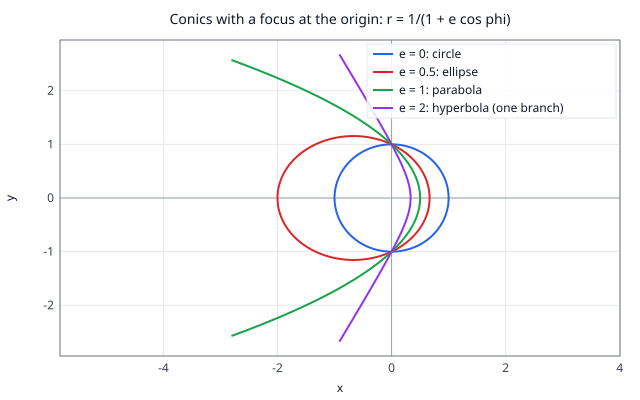

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [16]:
c0 = polarplot(1, phi, 0, 2*pi);
c1 = polarplot(1/(1 + 0.5*cos(phi)), phi, 0, 2*pi);
c2 = polarplot(1/(1 + cos(phi)), phi, -2.4, 2.4);
c3 = polarplot(1/(1 + 2*cos(phi)), phi, -1.9, 1.9);
p = legend(show(c0, c1, c2, c3), "e = 0: circle", "e = 0.5: ellipse", "e = 1: parabola", "e = 2: hyperbola (one branch)");
labels(title(p, "Conics with a focus at the origin: r = 1/(1 + e cos phi)"), "x", "y")

This is exactly the shape of orbits under gravity: Newton proved that a planet, comet or spacecraft moves on a conic
with the Sun at a focus. Planets have small eccentricities (Earth 0.017, Mars 0.093), Halley's comet 0.967, and
interstellar visitors like ʻOumuamua ($e = 1.2$) fly by on hyperbolas, never to return.

## Summary

* Distances come from Pythagoras; lines are $y = mx + c$; intersections are systems of equations.
* `implicitplot(equation, x, x0, x1, y, y0, y1)` draws curves given by equations, with equal scales.
* Ellipse, hyperbola and parabola: standard forms, foci, asymptotes.
* $Ax^2 + Bxy + Cy^2 + Dx + Ey + F = 0$ is an ellipse, parabola or hyperbola as $B^2 - 4AC$ is negative, zero or
  positive; eigenvalues of $\begin{pmatrix}A & B/2\\B/2 & C\end{pmatrix}$ untilt it; $\det Q = 0$ means degenerate.
* Eccentricity $e$ unites them: $r = 1/(1 + e\cos\varphi)$.

**Try it:** classify and draw $x^2 - 4xy + y^2 = 1$ and $4x^2 + 4xy + y^2 - 8x + 16y = 0$. Find the centre of
$x^2 + y^2 - 4x + 10y + 20 = 0$ by completing the square.

This is the end of the foundations path. Continue with [number theory](../number-theory/README.md),
[group theory](../group-theory/README.md), [linear algebra](../linear-algebra/README.md), or the
[differential geometry](../differential-geometry/README.md) path, which takes curves and surfaces much further.

## Sources

1. Apollonius of Perga, *Conics*, Books I–IV, transl. R. C. Taliaferro, Green Lion Press (2013).
2. R. Descartes, *La Géométrie*, appendix to the *Discours de la méthode* (1637).
3. I. Newton, *Philosophiæ Naturalis Principia Mathematica* (1687), Book I, Propositions 11–13: orbits under an inverse-square force are conics.
4. G. Strang, *Introduction to Linear Algebra*, 5th ed., Wellesley-Cambridge Press (2016). Section 6.5 (quadratic forms and the principal axis theorem).